# Visualització de les corbes diàries d'eòlica i preu del mercat diari

Autor: Leonel Fernando Nabaza Ruibal

Primer contacte amb les dades reals del mercat elèctric espanyol que farem servir per
aplicar la MFPCA (Happ & Greven, 2018). Tenim dues fonts independents, cadascuna a la
seva carpeta:

- `dades_esios/`: ESIOS (Red Eléctrica), eòlica cada 5 min i preu cada 15 min.
- `dades_energycharts/`: Energy-Charts (Fraunhofer ISE), eòlica i preu cada 15 min.

Cada carpeta es tracta per separat.


In [1]:
import os

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm
from matplotlib.colors import Normalize

# Carpetes de dades i nom de la font
FONTS = {
    "dades_esios": "ESIOS (REE)",
    "dades_energycharts": "Energy-Charts (Fraunhofer ISE)",
}


---
# Part 1 — Les dades com a dades funcionals

Cada dia $i = 1, \dots, n$ (en hora peninsular, de 00:00 a 24:00) és una observació
funcional **bivariant**:

$$
\mathbf{x}_i(t) = \big(x^{(1)}_i(t),\ x^{(2)}_i(t)\big), \qquad t \in [0, 1]
$$

on $x^{(1)}_i(t)$ és la generació eòlica (MW) i $x^{(2)}_i(t)$ el preu del mercat
diari (€/MWh). El temps s'ha reescalat a $[0,1]$ dividint els minuts del dia entre 1440.

Cada corba només s'observa en una malla discreta:

| Font | Eòlica | Preu |
|---|---|---|
| ESIOS | 288 punts (cada 5 min) | 96 punts (cada 15 min) |
| Energy-Charts | 96 punts (cada 15 min) | 96 punts (cada 15 min) |

Amb ESIOS, doncs, cada element té **la seva pròpia malla**, cosa que el marc de
Happ & Greven admet.


In [2]:
def carregar(carpeta):
    # Llegeix el .npz i retorna matrius (dies x punts), malles en hores i dates
    d = np.load(os.path.join(carpeta, "corbes_mfpca.npz"))
    # ESIOS té una malla per variable; Energy-Charts en té una de comuna
    t_eol = d["t_eolica"] if "t_eolica" in d.files else d["t"]
    t_pre = d["t_preu"] if "t_preu" in d.files else d["t"]
    return {
        "X_eol": d["X_eolica"], "t_eol": t_eol * 24,
        "X_pre": d["X_preu"], "t_pre": t_pre * 24,
        "dies": pd.to_datetime(d["dies"]),
    }


dades = {}
for carpeta, nom in FONTS.items():
    fitxer = os.path.join(carpeta, "corbes_mfpca.npz")
    if not os.path.exists(fitxer):
        print(f"{nom}: no s'ha trobat {fitxer}, s'omet")
        continue
    dades[carpeta] = carregar(carpeta)
    d = dades[carpeta]
    print(f"{nom}")
    print(f"  dies: {len(d['dies'])}  ({d['dies'].min().date()} -> {d['dies'].max().date()})")
    print(f"  eòlica: {d['X_eol'].shape}   rang {np.nanmin(d['X_eol']):.0f} - {np.nanmax(d['X_eol']):.0f} MW")
    print(f"  preu:   {d['X_pre'].shape}   rang {np.nanmin(d['X_pre']):.1f} - {np.nanmax(d['X_pre']):.1f} €/MWh")


ESIOS (REE)
  dies: 387  (2025-10-01 -> 2026-10-24)
  eòlica: (387, 288)   rang 262 - 19915 MW
  preu:   (387, 96)   rang -7.5 - 300.0 €/MWh
Energy-Charts (Fraunhofer ISE)
  dies: 385  (2025-10-01 -> 2026-10-23)
  eòlica: (385, 96)   rang 0 - 19840 MW
  preu:   (385, 96)   rang -7.5 - 300.0 €/MWh


---
# Part 2 — Totes les corbes diàries

Per a cada font dibuixem totes les corbes $x^{(j)}_i(t)$ superposades, amb el color
segons la data (de més antic, lila, a més recent, groc), i la **funció mitjana mostral**
en negre:

$$
\bar{x}^{(j)}(t) = \frac{1}{n} \sum_{i=1}^{n} x^{(j)}_i(t)
$$


In [3]:
def dibuixar_panell(ax, t, X, colors, titol, unitat):
    # Totes les corbes i la mitjana
    for fila, color in zip(X, colors):
        ax.plot(t, fila, color=color, lw=0.5, alpha=0.35)
    ax.plot(t, np.nanmean(X, axis=0), color="black", lw=2.2, label="Mitjana")
    ax.set_title(f"{titol}  ({X.shape[0]} dies, {X.shape[1]} punts/dia)")
    ax.set_xlabel("Hora del dia (hora peninsular)")
    ax.set_ylabel(unitat)
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 3))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")


def figura_corbes(d, nom_font):
    # Color segons la data
    num = mdates.date2num(d["dies"])
    norm = Normalize(vmin=num.min(), vmax=num.max())
    colors = cm.viridis(norm(num))

    fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
    dibuixar_panell(axs[0], d["t_eol"], d["X_eol"] / 1000, colors, "Generació eòlica", "GW")
    dibuixar_panell(axs[1], d["t_pre"], d["X_pre"], colors, "Preu mercat diari", "€/MWh")
    axs[1].axhline(0, color="grey", lw=0.8)

    # Barra de color amb les dates
    cb = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cm.viridis), ax=axs, shrink=0.9, pad=0.01)
    cb.ax.yaxis.set_major_locator(mdates.MonthLocator(interval=2))
    cb.ax.yaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

    inici, fi = d["dies"].min().strftime("%d/%m/%Y"), d["dies"].max().strftime("%d/%m/%Y")
    fig.suptitle(f"{nom_font}: corbes diàries {inici} – {fi}", fontsize=14)
    plt.show()


## 2.1 — ESIOS (Red Eléctrica)


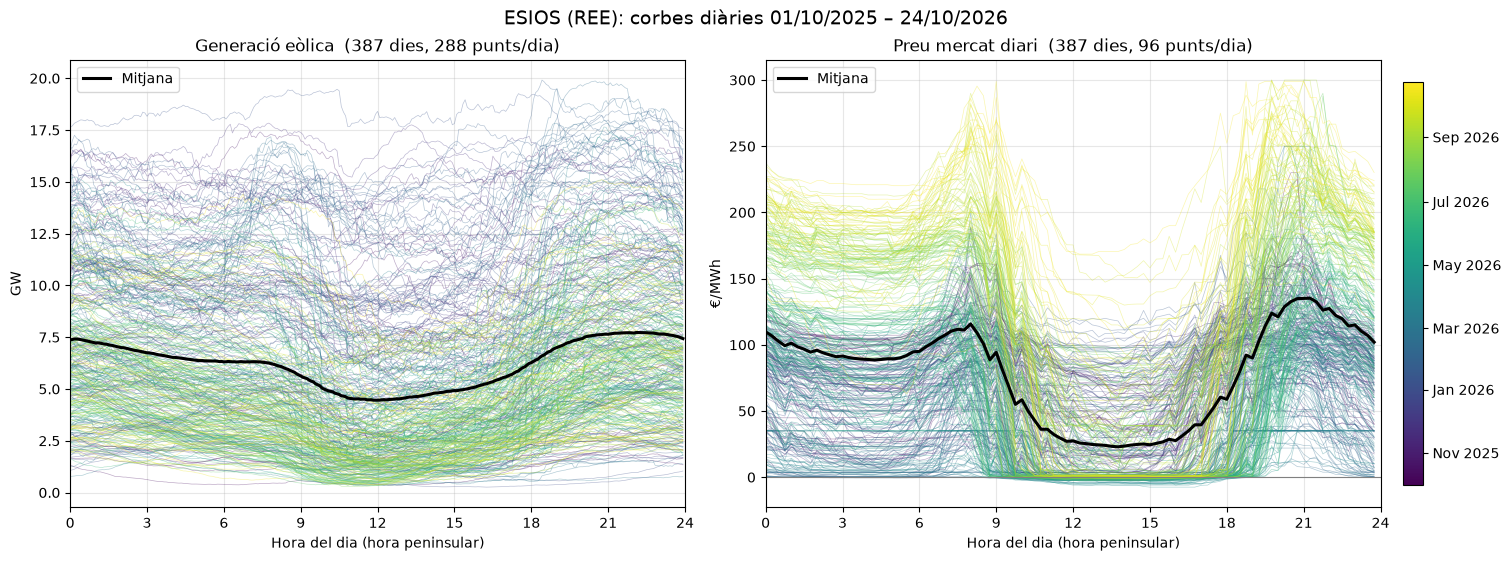

In [4]:
if "dades_esios" in dades:
    figura_corbes(dades["dades_esios"], FONTS["dades_esios"])
else:
    print("No hi ha dades d'ESIOS carregades")


## 2.2 — Energy-Charts (Fraunhofer ISE)


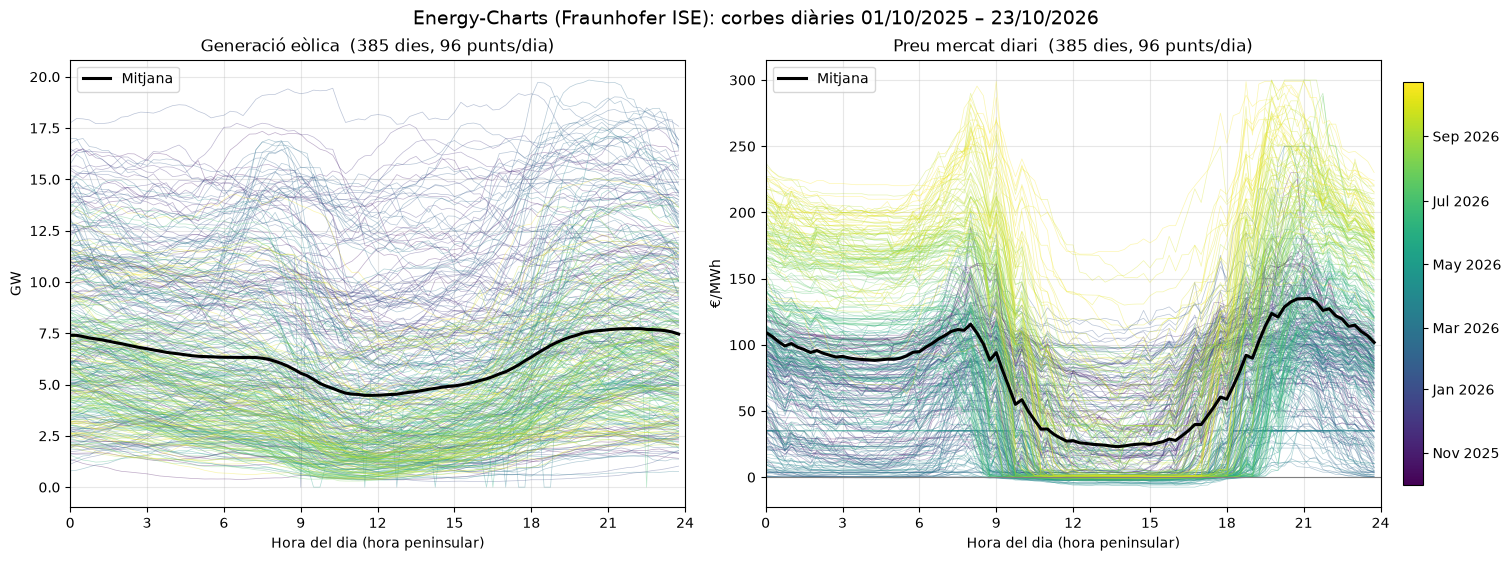

In [5]:
if "dades_energycharts" in dades:
    figura_corbes(dades["dades_energycharts"], FONTS["dades_energycharts"])
else:
    print("No hi ha dades d'Energy-Charts carregades")


---
# Part 3 — Mitjana i dispersió puntual

A més de la mitjana, mirem com varia la dispersió al llarg del dia amb la
**desviació típica puntual**:

$$
s^{(j)}(t) = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} \big(x^{(j)}_i(t) - \bar{x}^{(j)}(t)\big)^2}
$$

La banda $\bar{x}^{(j)}(t) \pm s^{(j)}(t)$ indica en quins moments del dia les corbes
són més diferents entre elles. Aquesta variabilitat és la que després descompondrà la
FPCA en components principals.


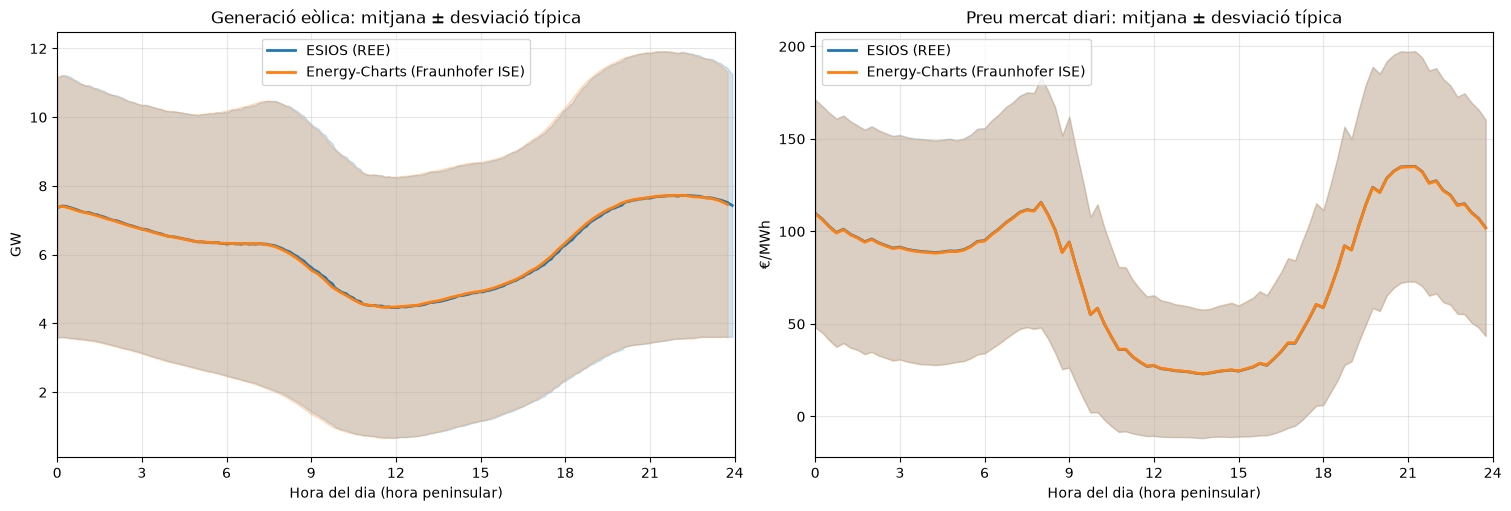

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
estils = {"dades_esios": "tab:blue", "dades_energycharts": "tab:orange"}

for carpeta, d in dades.items():
    color = estils[carpeta]
    for ax, t, X, esc in [(axs[0], d["t_eol"], d["X_eol"], 1000), (axs[1], d["t_pre"], d["X_pre"], 1)]:
        m = np.nanmean(X, axis=0) / esc
        s = np.nanstd(X, axis=0, ddof=1) / esc
        ax.plot(t, m, color=color, lw=2, label=FONTS[carpeta])
        ax.fill_between(t, m - s, m + s, color=color, alpha=0.2)

axs[0].set_title("Generació eòlica: mitjana ± desviació típica")
axs[0].set_ylabel("GW")
axs[1].set_title("Preu mercat diari: mitjana ± desviació típica")
axs[1].set_ylabel("€/MWh")
for ax in axs:
    ax.set_xlabel("Hora del dia (hora peninsular)")
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 3))
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()


---
# Conclusió

- **Eòlica:** les corbes diàries són molt variables d'un dia a l'altre; el nivell
  depèn sobretot del vent de cada dia més que de l'hora. La mitjana té un mínim cap al
  migdia i torna a pujar al vespre.
- **Preu:** té una forma diària molt marcada, amb una vall al migdia (preus propers a
  0 per la gran producció solar) i pics al matí i al vespre. També hi ha canvis de
  nivell clars entre mesos.
- Quan es tenen les dues fonts, les mitjanes i les bandes haurien de coincidir
  aproximadament; diferències grans indicarien un problema en alguna de les dues
  descàrregues.
- Abans d'aplicar la MFPCA caldrà tractar els valors anòmals (zeros d'eòlica a
  Energy-Charts) i normalitzar les dues variables, perquè tenen escales molt diferents.
